In [1]:
# 安裝地圖繪製套件 cartopy
!pip install cartopy

# 建立程式碼需要的資料夾結構
!mkdir -p plates
!mkdir -p ptwithin

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 33.3 MB/s eta 0:00:00


grid nodes generations are done!
mid points generations are done!
start processing polygon at 60 Ma
File generations completed! Now plotting...


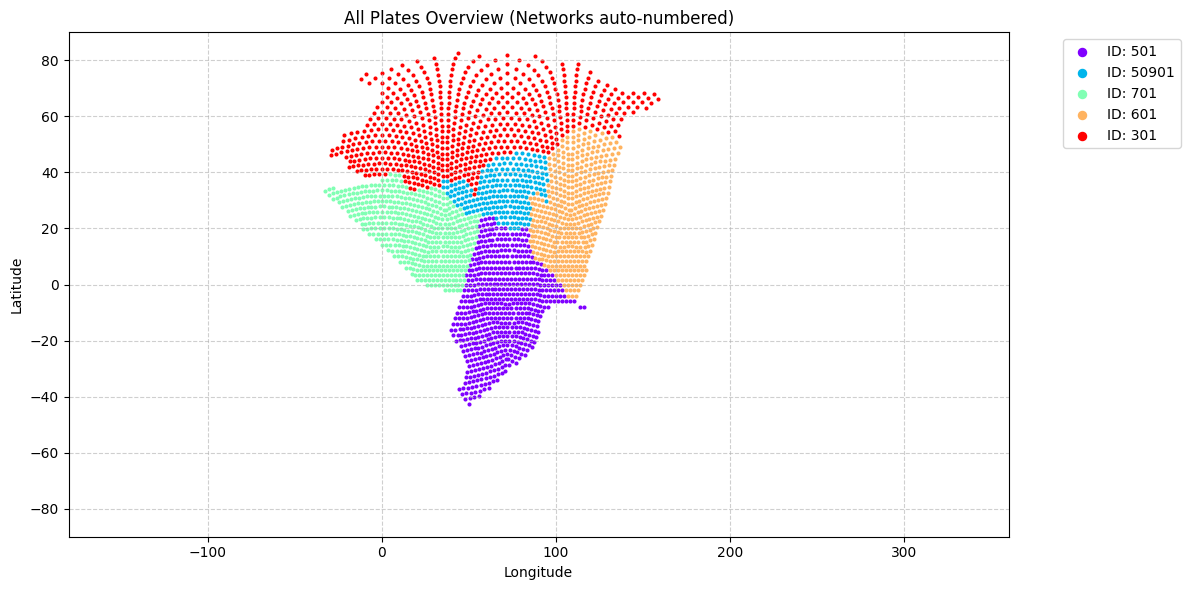

In [2]:
import numpy as np
from shapely.geometry import Point, Polygon
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import glob
import os
import re
import cartopy.crs as ccrs
import cartopy.feature as cfeature

#===================================================================
# Step1: Points
#===================================================================
def grdgen(nt):
    fifthpi = 0.4 * np.arcsin(1.0)
    w = 2.0 * np.arccos(1.0 / (2.0 * np.sin(fifthpi)))
    cosw = np.cos(w)
    sinw = np.sin(w)
    lvt = int(1.45 * np.log(nt))

    xn = np.zeros((nt + 1, nt + 1, 10, 3))

    for id in range(1, 11):
        sgn = 1.0
        if id >= 6:
            sgn = -1.0
        phi = (2 * (id % 5) - 3 + (id - 1) // 5) * fifthpi

        xn[0, 0, id - 1, 0] = 0.0
        xn[0, 0, id - 1, 1] = 0.0
        xn[0, 0, id - 1, 2] = sgn
        xn[nt, 0, id - 1, 0] = sinw * np.cos(phi)
        xn[nt, 0, id - 1, 1] = sinw * np.sin(phi)
        xn[nt, 0, id - 1, 2] = cosw * sgn
        xn[0, nt, id - 1, 0] = sinw * np.cos(phi + fifthpi + fifthpi)
        xn[0, nt, id - 1, 1] = sinw * np.sin(phi + fifthpi + fifthpi)
        xn[0, nt, id - 1, 2] = cosw * sgn
        xn[nt, nt, id - 1, 0] = sinw * np.cos(phi + fifthpi)
        xn[nt, nt, id - 1, 1] = sinw * np.sin(phi + fifthpi)
        xn[nt, nt, id - 1, 2] = -cosw * sgn

        for k in range(lvt):
            m = 2 ** k
            l = nt // m
            l2 = l // 2

            for j1 in range(m + 1):
                for j2 in range(m):
                    i1 = j1 * l
                    i2 = j2 * l + l2
                    xn[i1, i2, id - 1] = (xn[i1, i2 - l2, id - 1] + xn[i1, i2 + l2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])

            for j1 in range(m + 1):
                for j2 in range(m):
                    i1 = j2 * l + l2
                    i2 = j1 * l
                    xn[i1, i2, id - 1] = (xn[i1 - l2, i2, id - 1] + xn[i1 + l2, i2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])

            for j1 in range(m):
                for j2 in range(m):
                    i1 = j1 * l + l2
                    i2 = j2 * l + l2
                    xn[i1, i2, id - 1] = (xn[i1 - l2, i2 + l2, id - 1] + xn[i1 + l2, i2 - l2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])
    return xn

def midptgen(xn,nt):
    xm = np.zeros((nt, nt, 10, 3))
    for id in range(1, 11):
      for i1 in range(nt):
        for i2 in range(nt):
          xm[i1, i2, id - 1] = (xn[i1, i2, id - 1] + xn[i1 +1 , i2 + 1, id - 1]) / 2.0
          xm[i1, i2, id - 1] /= np.linalg.norm(xm[i1, i2, id - 1])
    return xm

def xyz2latlon(xm,nt):
    llm_ori = np.zeros((nt, nt, 10, 2))
    for id in range(10):
            for i in range(xm.shape[0]):
                for j in range(xm.shape[1]):
                    for k in range(xm.shape[2]):
                        x = xm[i, j, id, 0]
                        y = xm[i, j, id, 1]
                        z = xm[i, j, id, 2]
                        lon = np.degrees(np.arctan2(y, x))
                        lat = np.degrees(np.arcsin(z / np.linalg.norm([x, y, z])))
                        llm_ori [i, j, id, 0] = lon
                        llm_ori [i, j, id, 1] = lat
    return llm_ori

#===================================================================
# Plotting functions
#===================================================================
def plot_all_points(plot_data):
    if not plot_data:
        print("沒有收集到任何點可供畫圖。")
        return

    plt.figure(figsize=(12, 6))

    colors = cm.rainbow(np.linspace(0, 1, len(plot_data)))

    for idx, (attri, points) in enumerate(plot_data.items()):
        if not points:
            continue
        lons, lats = zip(*points)
        plt.scatter(lons, lats, marker=".", color=colors[idx], label=f"ID: {attri}", s=15)

    plt.xlim(-180, 360)
    plt.ylim(-90, 90)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("All Plates Overview (Networks auto-numbered)")

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', markerscale=3)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

#===================================================================
# Step2: Polygons (加入遞減計數器邏輯)
#===================================================================
def process_polygon(nnt, llm_ori, polygon_file_path, age, plot_data, network_id_counter):
        with open(polygon_file_path, 'r') as polygon_file:
            polygon_vertices = []
            ir_min = 125
            ir_max = 128

            # 初始設為 None，代表「目前還沒找到 ID」
            current_attri = None

            for line in polygon_file:
                if line.startswith('>'):
                    if polygon_vertices:
                        find_points_within_polygon(nnt, current_attri, ir_min, ir_max, llm_ori, polygon_vertices, age, plot_data)
                        polygon_vertices = []
                        # 處理完前一個後，重置為 None，準備讀取下一個
                        current_attri = None

                    match = re.search(r'reconstructionPlateId\s+(\d+)', line)
                    if match:
                       current_attri = int(match.group(1))
                else:
                    # 讀到第一個座標點時，標頭已經結束。檢查是否有找到 ID
                    if current_attri is None:
                        current_attri = network_id_counter
                        network_id_counter -= 1 # 賦值後，計數器減 1 (9999 -> 9998)

                    polygon_vertices.append(tuple(map(float, line.strip().split())))

            if polygon_vertices:
                if current_attri is None:
                    current_attri = network_id_counter
                    network_id_counter -= 1
                find_points_within_polygon(nnt, current_attri, ir_min, ir_max, llm_ori, polygon_vertices, age, plot_data)

        # 回傳處理完畢後的計數器數值，讓下一個檔案可以接續使用
        return network_id_counter

#===================================================================
# Step3: Points within polygons
#===================================================================
def wrap_longitude(lon):
    return lon if lon >= 0 else lon + 360

def find_points_within_polygon(nnt, attri, ir_min, ir_max, llm_ori, polygon_vertices, age, plot_data):
    llm = np.zeros((nt, nt, 10, 2))

    # 檢查相鄰的邊是否跨越換日線
    crosses_idl = False
    for i in range(len(polygon_vertices)):
        lon1 = polygon_vertices[i][0]
        # 取下一個點，若到陣列尾端則繞回起點
        lon2 = polygon_vertices[(i + 1) % len(polygon_vertices)][0]

        # 如果相鄰兩點的經度差大於 180，代表這條邊跨越了換日線
        if abs(lon1 - lon2) > 180:
            crosses_idl = True
            break

    if crosses_idl:
       polygon_vertices = [(wrap_longitude(lon), lat) for lon, lat in polygon_vertices]
       for i in range(llm_ori.shape[0]):
          for j in range(llm_ori.shape[1]):
            for id in range(llm_ori.shape[2]):
                lon = llm_ori[i, j, id, 0]
                lat = llm_ori[i, j, id, 1]
                llm[i, j, id, 0] = wrap_longitude(lon)
                llm[i, j, id, 1] = lat
    else:
        for i in range(llm_ori.shape[0]):
          for j in range(llm_ori.shape[1]):
            for id in range(llm_ori.shape[2]):
                lon = llm_ori[i, j, id, 0]
                lat = llm_ori[i, j, id, 1]
                llm[i, j, id, 0] = lon
                llm[i, j, id, 1] = lat

    polygon = Polygon(polygon_vertices)

    points_within_polygon = []
    output_files = {}

    for id in range(llm.shape[2]):
        process_id = 0
        for j in range(llm.shape[1]):
            i2 = j % nnt
            process_id = nnt * (j // nnt)

            for i in range(llm.shape[0]):
                point = llm[i, j, id]
                i1 = i % nnt
                if i1 == 0:
                    process_id = process_id + 1

                if Point(point).within(polygon):
                    points_within_polygon.append(point)

                    for ir in range(ir_min, ir_max+1):
                        if process_id not in output_files:
                            filename = f"./ptwithin/pt.{process_id-1:04}.{int(age):03d}"
                            output_files[process_id] = open(filename, "a")
                        output_files[process_id].write(f"{i1+1}, {i2+1}, {id+1}, {ir}, {attri}\n")

    for file_handle in output_files.values():
        file_handle.close()

    if points_within_polygon:
        if attri not in plot_data:
            plot_data[attri] = []
        plot_data[attri].extend(points_within_polygon)


#===================================================================
# Other functions
#===================================================================
def write_vtk(filename, xn):
    with open(filename, 'w') as f:
        f.write("# vtk DataFile Version 3.0\n")
        f.write("xyz2vtkpts\n")
        f.write("ASCII\n")
        f.write("DATASET POLYDATA\n")
        gridpoints = xn.shape[0] * xn.shape[1] * xn.shape[2]
        f.write("POINTS {} float\n".format(gridpoints))
        for id in range(10):
            for j in range(xn.shape[1]):
                for i in range(xn.shape[0]):
                    x = xn[i, j, id, 0]
                    y = xn[i, j, id, 1]
                    z = xn[i, j, id, 2]
                    f.write("{} {} {}\n".format(x, y, z))
        f.write("POINT_DATA {}\n".format(gridpoints))
        f.write("SCALARS process_id float\n")
        f.write("LOOKUP_TABLE default\n")
        for id in range(10):
            process_id = 0
            for j in range(xn.shape[1]):
                for i in range(xn.shape[0]):
                    i1 = i% 16
                    i2 = j% 16
                    if i1 == 0 and i2 == 0:
                        process_id = process_id + 1
                    f.write("{}\n".format(process_id))

#===================================================================
# Main functions
#===================================================================
nnt = 16
nt = 32 # 測試畫圖用，若要產出高解析度檔案請改回 256

polygon_file_paths = glob.glob("./plates/Polygon_*.xy")

xn = grdgen(nt)
print(f"grid nodes generations are done!")

xm = midptgen(xn, nt)
filename = "xm.vtk"
write_vtk(filename, xm)

llm_ori = xyz2latlon(xm,nt)
print(f"mid points generations are done!")

plot_data = {}

# 宣告一開始的計數器為 9999
current_network_id = 9999

for polygon_file_path in polygon_file_paths:
    age = os.path.splitext(os.path.basename(polygon_file_path))[0].split('_')[1]
    print(f"start processing polygon at {age} Ma")

    # 將 current_network_id 傳入函數，並將回傳更新後的數值接住
    # 這樣如果有好幾個檔案，編號就會一直遞減延續下去 (9999 -> 9998 -> 9997...)
    current_network_id = process_polygon(nnt, llm_ori, polygon_file_path, age, plot_data, current_network_id)

print(f"File generations completed! Now plotting...")

# 呼叫總圖繪製功能
plot_all_points(plot_data)

grid nodes generations are done!
mid points generations are done!
start processing polygon at 60 Ma
File generations completed! Now plotting...


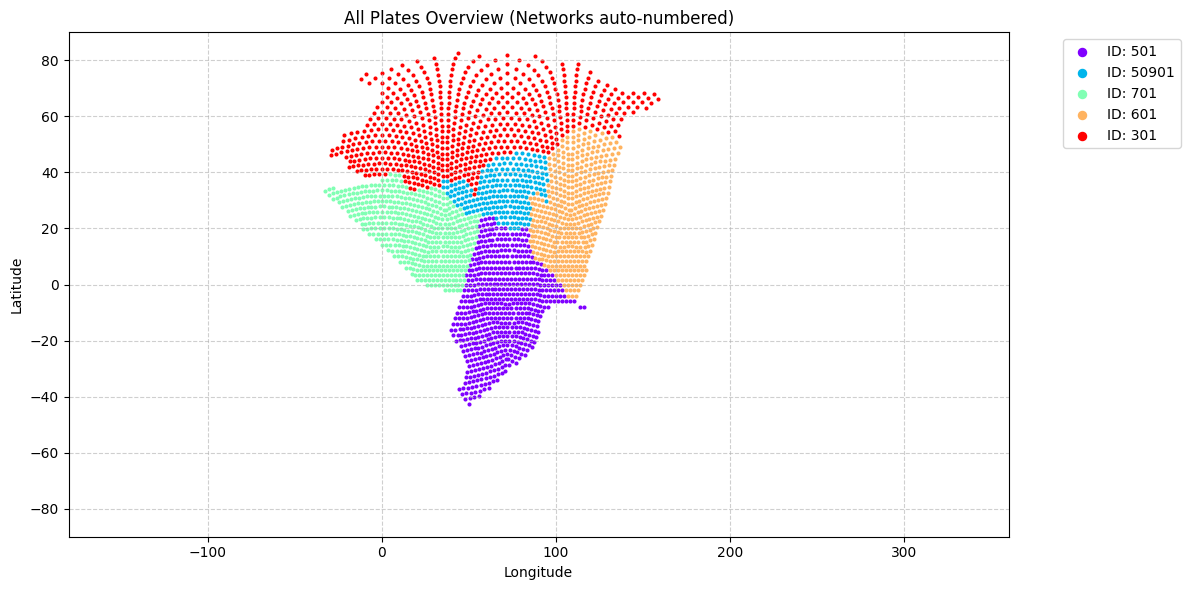

In [3]:
import numpy as np
from shapely.geometry import Point, Polygon
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import glob
import os
import re
import cartopy.crs as ccrs
import cartopy.feature as cfeature

#===================================================================
# Step1: Points
#===================================================================
def grdgen(nt):
    fifthpi = 0.4 * np.arcsin(1.0)
    w = 2.0 * np.arccos(1.0 / (2.0 * np.sin(fifthpi)))
    cosw = np.cos(w)
    sinw = np.sin(w)
    lvt = int(1.45 * np.log(nt))

    xn = np.zeros((nt + 1, nt + 1, 10, 3))

    for id in range(1, 11):
        sgn = 1.0
        if id >= 6:
            sgn = -1.0
        phi = (2 * (id % 5) - 3 + (id - 1) // 5) * fifthpi

        xn[0, 0, id - 1, 0] = 0.0
        xn[0, 0, id - 1, 1] = 0.0
        xn[0, 0, id - 1, 2] = sgn
        xn[nt, 0, id - 1, 0] = sinw * np.cos(phi)
        xn[nt, 0, id - 1, 1] = sinw * np.sin(phi)
        xn[nt, 0, id - 1, 2] = cosw * sgn
        xn[0, nt, id - 1, 0] = sinw * np.cos(phi + fifthpi + fifthpi)
        xn[0, nt, id - 1, 1] = sinw * np.sin(phi + fifthpi + fifthpi)
        xn[0, nt, id - 1, 2] = cosw * sgn
        xn[nt, nt, id - 1, 0] = sinw * np.cos(phi + fifthpi)
        xn[nt, nt, id - 1, 1] = sinw * np.sin(phi + fifthpi)
        xn[nt, nt, id - 1, 2] = -cosw * sgn

        for k in range(lvt):
            m = 2 ** k
            l = nt // m
            l2 = l // 2

            for j1 in range(m + 1):
                for j2 in range(m):
                    i1 = j1 * l
                    i2 = j2 * l + l2
                    xn[i1, i2, id - 1] = (xn[i1, i2 - l2, id - 1] + xn[i1, i2 + l2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])

            for j1 in range(m + 1):
                for j2 in range(m):
                    i1 = j2 * l + l2
                    i2 = j1 * l
                    xn[i1, i2, id - 1] = (xn[i1 - l2, i2, id - 1] + xn[i1 + l2, i2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])

            for j1 in range(m):
                for j2 in range(m):
                    i1 = j1 * l + l2
                    i2 = j2 * l + l2
                    xn[i1, i2, id - 1] = (xn[i1 - l2, i2 + l2, id - 1] + xn[i1 + l2, i2 - l2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])
    return xn

def midptgen(xn,nt):
    xm = np.zeros((nt, nt, 10, 3))
    for id in range(1, 11):
      for i1 in range(nt):
        for i2 in range(nt):
          xm[i1, i2, id - 1] = (xn[i1, i2, id - 1] + xn[i1 +1 , i2 + 1, id - 1]) / 2.0
          xm[i1, i2, id - 1] /= np.linalg.norm(xm[i1, i2, id - 1])
    return xm

def xyz2latlon(xm,nt):
    llm_ori = np.zeros((nt, nt, 10, 2))
    for id in range(10):
            for i in range(xm.shape[0]):
                for j in range(xm.shape[1]):
                    for k in range(xm.shape[2]):
                        x = xm[i, j, id, 0]
                        y = xm[i, j, id, 1]
                        z = xm[i, j, id, 2]
                        lon = np.degrees(np.arctan2(y, x))
                        lat = np.degrees(np.arcsin(z / np.linalg.norm([x, y, z])))
                        llm_ori [i, j, id, 0] = lon
                        llm_ori [i, j, id, 1] = lat
    return llm_ori

#===================================================================
# Plotting functions
#===================================================================
def plot_all_points(plot_data):
    if not plot_data:
        print("沒有收集到任何點可供畫圖。")
        return

    plt.figure(figsize=(12, 6))

    colors = cm.rainbow(np.linspace(0, 1, len(plot_data)))

    for idx, (attri, points) in enumerate(plot_data.items()):
        if not points:
            continue
        lons, lats = zip(*points)
        plt.scatter(lons, lats, marker=".", color=colors[idx], label=f"ID: {attri}", s=15)

    plt.xlim(-180, 360)
    plt.ylim(-90, 90)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title("All Plates Overview (Networks auto-numbered)")

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', markerscale=3)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

#===================================================================
# Step2: Polygons (加入遞減計數器邏輯)
#===================================================================
def process_polygon(nnt, llm_ori, polygon_file_path, age, plot_data, network_id_counter):
        with open(polygon_file_path, 'r') as polygon_file:
            polygon_vertices = []
            ir_min = 125
            ir_max = 128

            # 初始設為 None，代表「目前還沒找到 ID」
            current_attri = None

            for line in polygon_file:
                if line.startswith('>'):
                    if polygon_vertices:
                        find_points_within_polygon(nnt, current_attri, ir_min, ir_max, llm_ori, polygon_vertices, age, plot_data)
                        polygon_vertices = []
                        # 處理完前一個後，重置為 None，準備讀取下一個
                        current_attri = None

                    match = re.search(r'reconstructionPlateId\s+(\d+)', line)
                    if match:
                       current_attri = int(match.group(1))
                else:
                    # 讀到第一個座標點時，標頭已經結束。檢查是否有找到 ID
                    if current_attri is None:
                        current_attri = network_id_counter
                        network_id_counter -= 1 # 賦值後，計數器減 1 (9999 -> 9998)

                    polygon_vertices.append(tuple(map(float, line.strip().split())))

            if polygon_vertices:
                if current_attri is None:
                    current_attri = network_id_counter
                    network_id_counter -= 1
                find_points_within_polygon(nnt, current_attri, ir_min, ir_max, llm_ori, polygon_vertices, age, plot_data)

        # 回傳處理完畢後的計數器數值，讓下一個檔案可以接續使用
        return network_id_counter

#===================================================================
# Step3: Points within polygons
#===================================================================
def wrap_longitude(lon):
    return lon if lon >= 0 else lon + 360

def find_points_within_polygon(nnt, attri, ir_min, ir_max, llm_ori, polygon_vertices, age, plot_data):
    # 1. 取得多邊形的所有經度並排序
    lons = sorted([p[0] for p in polygon_vertices])

    # 2. 尋找這個板塊在地球上沒有覆蓋到的「最大經度缺口」
    max_gap = 0
    gap_center = 0
    n = len(lons)
    for i in range(n):
        if i == n - 1:
            # 處理跨越 -180/180 邊界的缺口
            gap = (lons[0] + 360) - lons[-1]
        else:
            gap = lons[i + 1] - lons[i]

        if gap > max_gap:
            max_gap = gap
            gap_center = lons[i] + gap / 2.0

    if gap_center > 180:
        gap_center -= 360

    # 3. 計算平移量，我們要把最大缺口對齊到地圖邊界 (+/- 180)
    shift = 180 - gap_center

    def shift_lon(lon):
        # 進行平移，並確保經度維持在 [-180, 180] 之間
        return (lon + shift + 180) % 360 - 180

    # 4. 把多邊形頂點平移到專屬的 2D 平面上
    shifted_vertices = [(shift_lon(lon), lat) for lon, lat in polygon_vertices]
    polygon = Polygon(shifted_vertices)

    points_within_polygon = []
    output_files = {}

    # 5. 判斷網格點 (不需要再另外建一個 llm 矩陣，直接邊讀邊判斷省記憶體)
    for id in range(llm_ori.shape[2]):
        process_id = 0
        for j in range(llm_ori.shape[1]):
            i2 = j % nnt
            process_id = nnt * (j // nnt)

            for i in range(llm_ori.shape[0]):
                i1 = i % nnt
                if i1 == 0:
                    process_id = process_id + 1

                # 原始點座標
                lon = llm_ori[i, j, id, 0]
                lat = llm_ori[i, j, id, 1]

                # 網格點也要做一樣的平移
                shifted_p_lon = shift_lon(lon)

                # 讓 Shapely 在沒有邊界干擾的平移空間中做判斷
                if Point(shifted_p_lon, lat).within(polygon):
                    # 判定在板塊內後，畫圖與存檔依然使用【原始座標】
                    points_within_polygon.append((lon, lat))

                    for ir in range(ir_min, ir_max+1):
                        if process_id not in output_files:
                            filename = f"./ptwithin/pt.{process_id-1:04}.{int(age):03d}"
                            output_files[process_id] = open(filename, "a")
                        output_files[process_id].write(f"{i1+1}, {i2+1}, {id+1}, {ir}, {attri}\n")

    for file_handle in output_files.values():
        file_handle.close()

    if points_within_polygon:
        if attri not in plot_data:
            plot_data[attri] = []
        plot_data[attri].extend(points_within_polygon)


#===================================================================
# Other functions
#===================================================================
def write_vtk(filename, xn):
    with open(filename, 'w') as f:
        f.write("# vtk DataFile Version 3.0\n")
        f.write("xyz2vtkpts\n")
        f.write("ASCII\n")
        f.write("DATASET POLYDATA\n")
        gridpoints = xn.shape[0] * xn.shape[1] * xn.shape[2]
        f.write("POINTS {} float\n".format(gridpoints))
        for id in range(10):
            for j in range(xn.shape[1]):
                for i in range(xn.shape[0]):
                    x = xn[i, j, id, 0]
                    y = xn[i, j, id, 1]
                    z = xn[i, j, id, 2]
                    f.write("{} {} {}\n".format(x, y, z))
        f.write("POINT_DATA {}\n".format(gridpoints))
        f.write("SCALARS process_id float\n")
        f.write("LOOKUP_TABLE default\n")
        for id in range(10):
            process_id = 0
            for j in range(xn.shape[1]):
                for i in range(xn.shape[0]):
                    i1 = i% 16
                    i2 = j% 16
                    if i1 == 0 and i2 == 0:
                        process_id = process_id + 1
                    f.write("{}\n".format(process_id))

#===================================================================
# Main functions
#===================================================================
nnt = 16
nt = 32 # 測試畫圖用，若要產出高解析度檔案請改回 256

polygon_file_paths = glob.glob("./plates/Polygon_*.xy")

xn = grdgen(nt)
print(f"grid nodes generations are done!")

xm = midptgen(xn, nt)
filename = "xm.vtk"
write_vtk(filename, xm)

llm_ori = xyz2latlon(xm,nt)
print(f"mid points generations are done!")

plot_data = {}

# 宣告一開始的計數器為 9999
current_network_id = 9999

for polygon_file_path in polygon_file_paths:
    age = os.path.splitext(os.path.basename(polygon_file_path))[0].split('_')[1]
    print(f"start processing polygon at {age} Ma")

    # 將 current_network_id 傳入函數，並將回傳更新後的數值接住
    # 這樣如果有好幾個檔案，編號就會一直遞減延續下去 (9999 -> 9998 -> 9997...)
    current_network_id = process_polygon(nnt, llm_ori, polygon_file_path, age, plot_data, current_network_id)

print(f"File generations completed! Now plotting...")

# 呼叫總圖繪製功能
plot_all_points(plot_data)

In [ ]:
import numpy as np
from shapely.geometry import Point, Polygon
import glob
import os
import re

#===================================================================
# Step1: Points
#===================================================================
def grdgen(nt):
    fifthpi = 0.4 * np.arcsin(1.0)
    w = 2.0 * np.arccos(1.0 / (2.0 * np.sin(fifthpi)))
    cosw = np.cos(w)
    sinw = np.sin(w)
    lvt = int(1.45 * np.log(nt))

    xn = np.zeros((nt + 1, nt + 1, 10, 3))

    for id in range(1, 11):
        sgn = 1.0
        if id >= 6:
            sgn = -1.0
        phi = (2 * (id % 5) - 3 + (id - 1) // 5) * fifthpi

        xn[0, 0, id - 1, 0] = 0.0
        xn[0, 0, id - 1, 1] = 0.0
        xn[0, 0, id - 1, 2] = sgn
        xn[nt, 0, id - 1, 0] = sinw * np.cos(phi)
        xn[nt, 0, id - 1, 1] = sinw * np.sin(phi)
        xn[nt, 0, id - 1, 2] = cosw * sgn
        xn[0, nt, id - 1, 0] = sinw * np.cos(phi + fifthpi + fifthpi)
        xn[0, nt, id - 1, 1] = sinw * np.sin(phi + fifthpi + fifthpi)
        xn[0, nt, id - 1, 2] = cosw * sgn
        xn[nt, nt, id - 1, 0] = sinw * np.cos(phi + fifthpi)
        xn[nt, nt, id - 1, 1] = sinw * np.sin(phi + fifthpi)
        xn[nt, nt, id - 1, 2] = -cosw * sgn

        for k in range(lvt):
            m = 2 ** k
            l = nt // m
            l2 = l // 2

            for j1 in range(m + 1):
                for j2 in range(m):
                    i1 = j1 * l
                    i2 = j2 * l + l2
                    xn[i1, i2, id - 1] = (xn[i1, i2 - l2, id - 1] + xn[i1, i2 + l2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])

            for j1 in range(m + 1):
                for j2 in range(m):
                    i1 = j2 * l + l2
                    i2 = j1 * l
                    xn[i1, i2, id - 1] = (xn[i1 - l2, i2, id - 1] + xn[i1 + l2, i2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])

            for j1 in range(m):
                for j2 in range(m):
                    i1 = j1 * l + l2
                    i2 = j2 * l + l2
                    xn[i1, i2, id - 1] = (xn[i1 - l2, i2 + l2, id - 1] + xn[i1 + l2, i2 - l2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])
    return xn


def midptgen(xn, nt):
    xm = np.zeros((nt, nt, 10, 3))
    for id in range(1, 11):
      for i1 in range(nt):
        for i2 in range(nt):
          xm[i1, i2, id - 1] = (xn[i1, i2, id - 1] + xn[i1 +1 , i2 + 1, id - 1]) / 2.0
          xm[i1, i2, id - 1] /= np.linalg.norm(xm[i1, i2, id - 1])
    return xm


def xyz2latlon(xm, nt):
    llm_ori = np.zeros((nt, nt, 10, 2))
    for id in range(10):
            for i in range(xm.shape[0]):
                for j in range(xm.shape[1]):
                    for k in range(xm.shape[2]):
                        x = xm[i, j, id, 0]
                        y = xm[i, j, id, 1]
                        z = xm[i, j, id, 2]
                        lon = np.degrees(np.arctan2(y, x))
                        lat = np.degrees(np.arcsin(z / np.linalg.norm([x, y, z])))
                        llm_ori[i, j, id, 0] = lon
                        llm_ori[i, j, id, 1] = lat
    return llm_ori


#===================================================================
# Step2: Polygons (Network auto-numbering logic)
#===================================================================
def process_polygon(nnt, llm_ori, polygon_file_path, age, network_id_counter):
        with open(polygon_file_path, 'r') as polygon_file:
            polygon_vertices = []
            ir_min = 125
            ir_max = 128

            current_attri = None

            for line in polygon_file:
                if line.startswith('>'):
                    if polygon_vertices:
                        find_points_within_polygon(nnt, current_attri, ir_min, ir_max, llm_ori, polygon_vertices, age)
                        polygon_vertices = []
                        current_attri = None

                    match = re.search(r'reconstructionPlateId\s+(\d+)', line)
                    if match:
                       current_attri = int(match.group(1))
                else:
                    if current_attri is None:
                        current_attri = network_id_counter
                        network_id_counter -= 1

                    polygon_vertices.append(tuple(map(float, line.strip().split())))

            if polygon_vertices:
                if current_attri is None:
                    current_attri = network_id_counter
                    network_id_counter -= 1
                find_points_within_polygon(nnt, current_attri, ir_min, ir_max, llm_ori, polygon_vertices, age)

        return network_id_counter


#===================================================================
# Step3: Points within polygons
#===================================================================
def wrap_longitude(lon):
    return lon if lon >= 0 else lon + 360

def find_points_within_polygon(nnt, attri, ir_min, ir_max, llm_ori, polygon_vertices, age):
    llm = np.zeros((nt, nt, 10, 2))

    longitudes = [p[0] for p in polygon_vertices]
    crosses_idl = (max(longitudes) - min(longitudes)) > 180

    if crosses_idl:
       polygon_vertices = [(wrap_longitude(lon), lat) for lon, lat in polygon_vertices]
       for i in range(llm_ori.shape[0]):
          for j in range(llm_ori.shape[1]):
            for id in range(llm_ori.shape[2]):
                lon = llm_ori[i, j, id, 0]
                lat = llm_ori[i, j, id, 1]
                llm[i, j, id, 0] = wrap_longitude(lon)
                llm[i, j, id, 1] = lat
    else:
        for i in range(llm_ori.shape[0]):
          for j in range(llm_ori.shape[1]):
            for id in range(llm_ori.shape[2]):
                lon = llm_ori[i, j, id, 0]
                lat = llm_ori[i, j, id, 1]
                llm[i, j, id, 0] = lon
                llm[i, j, id, 1] = lat

    polygon = Polygon(polygon_vertices)
    output_files = {}

    for id in range(llm.shape[2]):
        process_id = 0
        for j in range(llm.shape[1]):
            i2 = j % nnt
            process_id = nnt * (j // nnt)

            for i in range(llm.shape[0]):
                point = llm[i, j, id]
                i1 = i % nnt
                if i1 == 0:
                    process_id = process_id + 1

                if Point(point).within(polygon):
                    for ir in range(ir_min, ir_max+1):
                        if process_id not in output_files:
                            filename = f"./ptwithin/pt.{process_id-1:04}.{int(age):03d}"
                            output_files[process_id] = open(filename, "a")
                        output_files[process_id].write(f"{i1+1}, {i2+1}, {id+1}, {ir}, {attri}\n")

    for file_handle in output_files.values():
        file_handle.close()


#===================================================================
# Other functions
#===================================================================
def write_vtk(filename, xn):
    with open(filename, 'w') as f:
        f.write("# vtk DataFile Version 3.0\n")
        f.write("xyz2vtkpts\n")
        f.write("ASCII\n")
        f.write("DATASET POLYDATA\n")
        gridpoints = xn.shape[0] * xn.shape[1] * xn.shape[2]
        f.write("POINTS {} float\n".format(gridpoints))
        for id in range(10):
            for j in range(xn.shape[1]):
                for i in range(xn.shape[0]):
                    x = xn[i, j, id, 0]
                    y = xn[i, j, id, 1]
                    z = xn[i, j, id, 2]
                    f.write("{} {} {}\n".format(x, y, z))
        f.write("POINT_DATA {}\n".format(gridpoints))
        f.write("SCALARS process_id float\n")
        f.write("LOOKUP_TABLE default\n")
        for id in range(10):
            process_id = 0
            for j in range(xn.shape[1]):
                for i in range(xn.shape[0]):
                    i1 = i% 16
                    i2 = j% 16
                    if i1 == 0 and i2 == 0:
                        process_id = process_id + 1
                    f.write("{}\n".format(process_id))


#===================================================================
# Main functions
#===================================================================
nnt = 16
nt = 256  # 已經為你設定為高解析度網格

polygon_file_paths = glob.glob("./plates/Polygon_*.xy")

xn = grdgen(nt)
print(f"grid nodes generations are done!")

xm = midptgen(xn, nt)
filename = "xm.vtk"
write_vtk(filename, xm)

llm_ori = xyz2latlon(xm, nt)
print(f"mid points generations are done!")

# 宣告一開始的計數器為 9999，供找不到 ID 的特徵遞減使用
current_network_id = 9999

for polygon_file_path in polygon_file_paths:
    age = os.path.splitext(os.path.basename(polygon_file_path))[0].split('_')[1]
    print(f"start processing polygon at {age} Ma")

    current_network_id = process_polygon(nnt, llm_ori, polygon_file_path, age, current_network_id)

print(f"File generations completed!")

grid nodes generations are done!
mid points generations are done!
start processing polygon at 45 Ma
File generations completed!


In [5]:
import numpy as np
from shapely.geometry import Point, Polygon
import glob
import os
import re

#===================================================================
# Step1: Points
#===================================================================
def grdgen(nt):
    fifthpi = 0.4 * np.arcsin(1.0)
    w = 2.0 * np.arccos(1.0 / (2.0 * np.sin(fifthpi)))
    cosw = np.cos(w)
    sinw = np.sin(w)
    lvt = int(1.45 * np.log(nt))

    xn = np.zeros((nt + 1, nt + 1, 10, 3))

    for id in range(1, 11):
        sgn = 1.0
        if id >= 6:
            sgn = -1.0
        phi = (2 * (id % 5) - 3 + (id - 1) // 5) * fifthpi

        xn[0, 0, id - 1, 0] = 0.0
        xn[0, 0, id - 1, 1] = 0.0
        xn[0, 0, id - 1, 2] = sgn
        xn[nt, 0, id - 1, 0] = sinw * np.cos(phi)
        xn[nt, 0, id - 1, 1] = sinw * np.sin(phi)
        xn[nt, 0, id - 1, 2] = cosw * sgn
        xn[0, nt, id - 1, 0] = sinw * np.cos(phi + fifthpi + fifthpi)
        xn[0, nt, id - 1, 1] = sinw * np.sin(phi + fifthpi + fifthpi)
        xn[0, nt, id - 1, 2] = cosw * sgn
        xn[nt, nt, id - 1, 0] = sinw * np.cos(phi + fifthpi)
        xn[nt, nt, id - 1, 1] = sinw * np.sin(phi + fifthpi)
        xn[nt, nt, id - 1, 2] = -cosw * sgn

        for k in range(lvt):
            m = 2 ** k
            l = nt // m
            l2 = l // 2

            for j1 in range(m + 1):
                for j2 in range(m):
                    i1 = j1 * l
                    i2 = j2 * l + l2
                    xn[i1, i2, id - 1] = (xn[i1, i2 - l2, id - 1] + xn[i1, i2 + l2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])

            for j1 in range(m + 1):
                for j2 in range(m):
                    i1 = j2 * l + l2
                    i2 = j1 * l
                    xn[i1, i2, id - 1] = (xn[i1 - l2, i2, id - 1] + xn[i1 + l2, i2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])

            for j1 in range(m):
                for j2 in range(m):
                    i1 = j1 * l + l2
                    i2 = j2 * l + l2
                    xn[i1, i2, id - 1] = (xn[i1 - l2, i2 + l2, id - 1] + xn[i1 + l2, i2 - l2, id - 1]) / 2.0
                    xn[i1, i2, id - 1] /= np.linalg.norm(xn[i1, i2, id - 1])
    return xn


def midptgen(xn, nt):
    xm = np.zeros((nt, nt, 10, 3))
    for id in range(1, 11):
      for i1 in range(nt):
        for i2 in range(nt):
          xm[i1, i2, id - 1] = (xn[i1, i2, id - 1] + xn[i1 + 1 , i2 + 1, id - 1]) / 2.0
          xm[i1, i2, id - 1] /= np.linalg.norm(xm[i1, i2, id - 1])
    return xm


def xyz2latlon(xm, nt):
    llm_ori = np.zeros((nt, nt, 10, 2))
    for id in range(10):
            for i in range(xm.shape[0]):
                for j in range(xm.shape[1]):
                    for k in range(xm.shape[2]):
                        x = xm[i, j, id, 0]
                        y = xm[i, j, id, 1]
                        z = xm[i, j, id, 2]
                        lon = np.degrees(np.arctan2(y, x))
                        lat = np.degrees(np.arcsin(z / np.linalg.norm([x, y, z])))
                        llm_ori[i, j, id, 0] = lon
                        llm_ori[i, j, id, 1] = lat
    return llm_ori


#===================================================================
# Step2: Polygons (Network auto-numbering logic)
#===================================================================
def process_polygon(nnt, llm_ori, polygon_file_path, age, network_id_counter):
        with open(polygon_file_path, 'r') as polygon_file:
            polygon_vertices = []
            ir_min = 125
            ir_max = 128

            current_attri = None

            for line in polygon_file:
                if line.startswith('>'):
                    if polygon_vertices:
                        find_points_within_polygon(nnt, current_attri, ir_min, ir_max, llm_ori, polygon_vertices, age)
                        polygon_vertices = []
                        current_attri = None

                    match = re.search(r'reconstructionPlateId\s+(\d+)', line)
                    if match:
                       current_attri = int(match.group(1))
                else:
                    if current_attri is None:
                        current_attri = network_id_counter
                        network_id_counter -= 1

                    polygon_vertices.append(tuple(map(float, line.strip().split())))

            if polygon_vertices:
                if current_attri is None:
                    current_attri = network_id_counter
                    network_id_counter -= 1
                find_points_within_polygon(nnt, current_attri, ir_min, ir_max, llm_ori, polygon_vertices, age)

        return network_id_counter


#===================================================================
# Step3: Points within polygons (Dynamic Shift Logic Included)
#===================================================================
def find_points_within_polygon(nnt, attri, ir_min, ir_max, llm_ori, polygon_vertices, age):
    # 1. 取得多邊形的所有經度並排序
    lons = sorted([p[0] for p in polygon_vertices])

    if not lons:
        return

    # 2. 尋找這個板塊在地球上沒有覆蓋到的「最大經度缺口」
    max_gap = 0
    gap_center = 0
    n = len(lons)
    for i in range(n):
        if i == n - 1:
            # 處理跨越 -180/180 邊界的缺口
            gap = (lons[0] + 360) - lons[-1]
        else:
            gap = lons[i + 1] - lons[i]

        if gap > max_gap:
            max_gap = gap
            gap_center = lons[i] + gap / 2.0

    if gap_center > 180:
        gap_center -= 360

    # 3. 計算平移量，把最大缺口對齊到地圖邊界 (+/- 180)
    shift = 180 - gap_center

    def shift_lon(lon):
        # 進行平移，並確保經度維持在 [-180, 180] 之間
        return (lon + shift + 180) % 360 - 180

    # 4. 把多邊形頂點平移到專屬的 2D 平面上
    shifted_vertices = [(shift_lon(lon), lat) for lon, lat in polygon_vertices]
    polygon = Polygon(shifted_vertices)

    output_files = {}

    # 確保輸出目錄存在，避免 open() 報錯
    os.makedirs("./ptwithin", exist_ok=True)

    # 5. 判斷網格點並寫入檔案
    for id in range(llm_ori.shape[2]):
        process_id = 0
        for j in range(llm_ori.shape[1]):
            i2 = j % nnt
            process_id = nnt * (j // nnt)

            for i in range(llm_ori.shape[0]):
                i1 = i % nnt
                if i1 == 0:
                    process_id = process_id + 1

                # 原始點座標
                lon = llm_ori[i, j, id, 0]
                lat = llm_ori[i, j, id, 1]

                # 網格點也要做一樣的平移
                shifted_p_lon = shift_lon(lon)

                # 讓 Shapely 在沒有邊界干擾的平移空間中做判斷
                if Point(shifted_p_lon, lat).within(polygon):
                    for ir in range(ir_min, ir_max+1):
                        if process_id not in output_files:
                            filename = f"./ptwithin/pt.{process_id-1:04}.{int(age):03d}"
                            output_files[process_id] = open(filename, "a")
                        output_files[process_id].write(f"{i1+1}, {i2+1}, {id+1}, {ir}, {attri}\n")

    for file_handle in output_files.values():
        file_handle.close()


#===================================================================
# Other functions
#===================================================================
def write_vtk(filename, xn):
    with open(filename, 'w') as f:
        f.write("# vtk DataFile Version 3.0\n")
        f.write("xyz2vtkpts\n")
        f.write("ASCII\n")
        f.write("DATASET POLYDATA\n")
        gridpoints = xn.shape[0] * xn.shape[1] * xn.shape[2]
        f.write("POINTS {} float\n".format(gridpoints))
        for id in range(10):
            for j in range(xn.shape[1]):
                for i in range(xn.shape[0]):
                    x = xn[i, j, id, 0]
                    y = xn[i, j, id, 1]
                    z = xn[i, j, id, 2]
                    f.write("{} {} {}\n".format(x, y, z))
        f.write("POINT_DATA {}\n".format(gridpoints))
        f.write("SCALARS process_id float\n")
        f.write("LOOKUP_TABLE default\n")
        for id in range(10):
            process_id = 0
            for j in range(xn.shape[1]):
                for i in range(xn.shape[0]):
                    i1 = i % 16
                    i2 = j % 16
                    if i1 == 0 and i2 == 0:
                        process_id = process_id + 1
                    f.write("{}\n".format(process_id))


#===================================================================
# Main functions
#===================================================================
if __name__ == "__main__":
    nnt = 16
    nt = 256  # 產出高解析度檔案

    polygon_file_paths = glob.glob("./plates/Polygon_*.xy")

    xn = grdgen(nt)
    print(f"grid nodes generations are done!")

    xm = midptgen(xn, nt)
    filename = "xm.vtk"
    write_vtk(filename, xm)

    llm_ori = xyz2latlon(xm, nt)
    print(f"mid points generations are done!")

    # 宣告一開始的計數器為 9999，供找不到 ID 的特徵遞減使用
    current_network_id = 9999

    for polygon_file_path in polygon_file_paths:
        age_str = os.path.splitext(os.path.basename(polygon_file_path))[0].split('_')[1]
        age = float(age_str)  # 確保 age 可以轉為數值格式
        print(f"start processing polygon at {age} Ma")

        current_network_id = process_polygon(nnt, llm_ori, polygon_file_path, age, current_network_id)

    print(f"File generations completed!")

grid nodes generations are done!
mid points generations are done!
start processing polygon at 60.0 Ma
File generations completed!


In [6]:
# 1. 將 ptwithin 資料夾內的所有的檔案壓縮成一個叫做 ptwithin_result.zip 的壓縮檔
!zip -r ptwithin_result.zip ptwithin/

# 2. 自動觸發瀏覽器下載
from google.colab import files
files.download('ptwithin_result.zip')

# 如果你也想把 xm.vtk 一起下載，可以把下面這行最前面的 # 刪掉
# files.download('xm.vtk')

  adding: ptwithin/ (stored 0%)
  adding: ptwithin/pt.0108.060 (deflated 89%)
  adding: ptwithin/pt.0230.060 (deflated 89%)
  adding: ptwithin/pt.0176.060 (deflated 89%)
  adding: ptwithin/pt.0079.060 (deflated 89%)
  adding: ptwithin/pt.0130.060 (deflated 89%)
  adding: ptwithin/pt.0010.060 (deflated 89%)
  adding: ptwithin/pt.0086.060 (deflated 89%)
  adding: ptwithin/pt.0163.060 (deflated 89%)
  adding: ptwithin/pt.0115.060 (deflated 89%)
  adding: ptwithin/pt.0011.060 (deflated 89%)
  adding: ptwithin/pt.0057.060 (deflated 89%)
  adding: ptwithin/pt.0058.060 (deflated 89%)
  adding: ptwithin/pt.0112.060 (deflated 89%)
  adding: ptwithin/pt.0092.060 (deflated 89%)
  adding: ptwithin/pt.0189.060 (deflated 89%)
  adding: ptwithin/pt.0202.060 (deflated 89%)
  adding: ptwithin/pt.0241.060 (deflated 89%)
  adding: ptwithin/pt.0065.060 (deflated 89%)
  adding: ptwithin/pt.0150.060 (deflated 89%)
  adding: ptwithin/pt.0030.060 (deflated 89%)
  adding: ptwithin/pt.0037.060 (deflated 89%)
  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>